# 📈 Sistem Pakar: Prediksi Waktu *Buy / Sell / Hold* Saham Berdasarkan Berita Ekonomi
**Final Exam – Mini Project & Reporting (UKRIDA)** · Topik: *Predicting when to buy or sell stocks based on economic news*

Notebook ini berisi **program lengkap** + bahan **laporan** (flowchart, arsitektur sistem, knowledge base, minimum 20 test case).

| Komponen | Isi |
|---|---|
| Dataset | `sp500_headlines_2008_2024.csv` — 19.127 headline berita S&P 500 (2008–2024) + harga penutupan (`CP`) |
| Metode | *Rule-based expert system* (forward chaining + **Certainty Factor** MYCIN) dengan input sentimen berita berbasis kamus & aspek |
| Output | Rekomendasi **BUY / SELL / HOLD** + penjelasan aturan mana yang aktif |

### Bagaimana 3 referensi dipakai
| Referensi | Dipakai untuk |
|---|---|
| **Barbaglia, Consoli & Manzan (2022)** – *Forecasting with Economic News* | Ide *Fine-Grained Aspect-Based Sentiment (FiGAS)*: kamus sentimen berskala **[-1, +1]**, *Token of Interest* (ekonomi, sektor keuangan, inflasi, manufaktur, kebijakan moneter, pengangguran), penanganan negasi. |
| **Maghyereh & Abdoh (2022)** – *Can news-based economic sentiment predict bubbles in precious metal markets?* | Landasan aturan pakar: sentimen sangat bearish → peluang kontrarian, euforia + harga jenuh → risiko *bubble*, kebijakan moneter longgar → aset berisiko naik, pengaruh inflasi & suku bunga. |
| **Dornadula et al. (2023)** – *Survey of COVID-19 Detection from Chest X-Rays* | Bukan domain yang sama; dipakai untuk **metodologi evaluasi** (accuracy, precision, recall, F1, confusion matrix), perbandingan dengan model ML lain, serta diskusi keterbatasan (data kecil, overfitting, generalisasi). |

> ⚠️ **Catatan penting:** ini proyek akademik. Hasil bukan saran investasi.

## 1. Setup & Memuat Dataset

In [1]:
import os, re, math, glob, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon, FancyArrowPatch
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
os.makedirs("figs", exist_ok=True)

CSV_NAME = "sp500_headlines_2008_2024.csv"

def find_dataset():
    """Cari CSV di folder kerja / zip / Colab / folder upload."""
    if os.path.exists(CSV_NAME): return CSV_NAME
    for folder in [".", "/content", "/mnt/user-data/uploads", "data"]:
        for z in glob.glob(os.path.join(folder, "*.zip")):
            try:
                with zipfile.ZipFile(z) as zf:
                    if CSV_NAME in zf.namelist():
                        zf.extract(CSV_NAME, "."); return CSV_NAME
            except zipfile.BadZipFile: pass
        p = os.path.join(folder, CSV_NAME)
        if os.path.exists(p): return p
    try:   # Google Colab: upload manual
        from google.colab import files
        print("Dataset tidak ditemukan, silakan upload archive.zip / CSV ...")
        up = files.upload()
        for name in up:
            if name.endswith(".zip"):
                with zipfile.ZipFile(name) as zf: zf.extract(CSV_NAME, ".")
        return CSV_NAME
    except ImportError:
        raise FileNotFoundError(f"Letakkan {CSV_NAME} (atau archive.zip) di folder yang sama dengan notebook ini.")

df = pd.read_csv(find_dataset(), parse_dates=["Date"])
n_raw = len(df)
df = df.drop_duplicates(["Title", "Date"]).reset_index(drop=True)      # headline yang sama pada hari yang sama dihitung sekali
print(f"Duplikat dibuang : {n_raw-len(df)} baris")
print("Ukuran data :", df.shape)
print("Rentang     :", df.Date.min().date(), "→", df.Date.max().date())
print("Hari unik   :", df.Date.nunique())
df.head()

Duplikat dibuang : 974 baris
Ukuran data : (18153, 3)
Rentang     : 2008-01-02 → 2024-03-04
Hari unik   : 3507


,Title,Date,CP
0,"JPMorgan Predicts 2008 Will Be ""Nothing But Net""",2008-01-02,1447.16
1,Dow Tallies Biggest First-session-of-year Point Drop Ever,2008-01-02,1447.16
2,2008 predictions for the S&P 500,2008-01-02,1447.16
3,"U.S. Stocks Higher After Economic Data, Monsanto Outlook",2008-01-03,1447.16
4,U.S. Stocks Climb As Hopes Increase For More Fed Moves,2008-01-07,1416.18


## 2. Eksplorasi Data (EDA)
Dua hal penting: (1) jumlah headline **tidak merata** (2008–2010 sangat sedikit, 2023 sangat banyak), (2) `CP` adalah harga penutupan S&P 500 pada tanggal headline.

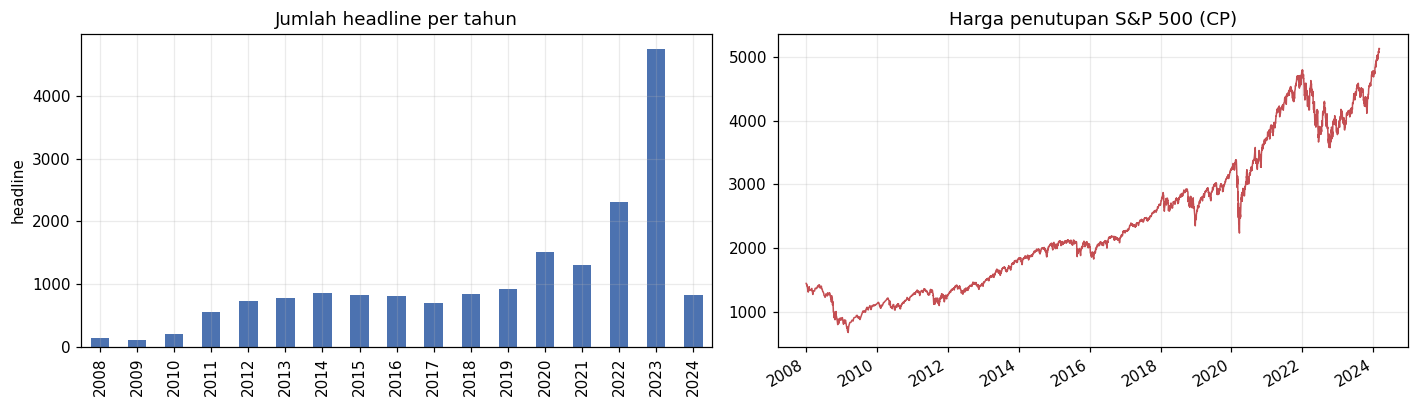

Missing value:
 Title    0
Date     0
CP       0


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
df.groupby(df.Date.dt.year).size().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Jumlah headline per tahun"); ax[0].set_xlabel(""); ax[0].set_ylabel("headline")
px = df.groupby("Date").CP.first()
px.plot(ax=ax[1], color="#C44E52", lw=1); ax[1].set_title("Harga penutupan S&P 500 (CP)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig("figs/eda.png"); plt.show()
print("Missing value:\n", df.isna().sum().to_string())

## 3. Modul Sentimen Berita (terinspirasi FiGAS)
Langkah per headline:
1. **Normalisasi & frasa** – `"rate cut"` → `ratecut`, `"bear market"` → `bearmarket`, dst.
2. **Skor kata** dari kamus ekonomi-keuangan (rentang **−1…+1**, ide Barbaglia et al. yang mengembangkan kamus Loughran-McDonald).
3. **Modifikasi**: *intensifier* (sharply, biggest ×1.3–1.5), *dampener* (slightly ×0.6), **negasi** (not, no → ×−0.8).
4. **Aspect-based**: hanya kata di sekitar **Token of Interest** (jendela ±5 kata, bobot 1/(1+jarak)) yang dihitung untuk aspek tsb.
5. **Pembalikan polaritas** untuk ToI tertentu: *"unemployment **falls**"* = baik, *"inflation **rises**"* = buruk.

> **Penyederhanaan jujur:** paper aslinya memakai *dependency parsing* spaCy (aturan `amod`, `dobj`, dst.). Di sini dipakai jendela kata agar notebook ringan dan tanpa unduhan model bahasa.

In [3]:
LEXICON = {
 # --- positif ---
 'rally':.6,'rallies':.6,'rallied':.6,'surge':.7,'surges':.7,'surged':.7,'soar':.8,'soars':.8,'soared':.8,'jump':.5,'jumps':.5,'jumped':.5,
 'gain':.5,'gains':.5,'gained':.5,'rise':.4,'rises':.4,'rose':.4,'rising':.4,'climb':.5,'climbs':.5,'climbed':.5,'higher':.4,'up':.2,
 'advance':.4,'advances':.4,'record':.5,'boom':.7,'booming':.7,'strong':.5,'stronger':.6,'strength':.5,'robust':.6,'upbeat':.6,
 'optimism':.6,'optimistic':.6,'bullish':.7,'bull':.5,'recovery':.6,'recover':.5,'recovers':.5,'rebound':.6,'rebounds':.6,'growth':.5,
 'expansion':.5,'expand':.4,'profit':.5,'profits':.5,'beat':.4,'beats':.4,'upgrade':.5,'upgrades':.5,'confidence':.4,'improve':.5,'improves':.5,
 'improved':.5,'improving':.5,'stimulus':.5,'easing':.4,'cut':.1,'cuts':.1,'positive':.4,'resilient':.5,'resilience':.5,'boost':.5,'boosts':.5,
 'opportunity':.4,'opportunities':.4,'hope':.3,'hopes':.3,'buy':.3,'outperform':.5,'calm':.3,'relief':.5,'lift':.4,'lifts':.4,'steady':.2,
 'stable':.3,'stabilize':.4,'stabilizes':.4,'upside':.5,'winners':.4,'winner':.4,'breakout':.5,'healthy':.5,'cheer':.4,'cheers':.4,
 # --- negatif ---
 'plunge':-.8,'plunges':-.8,'plunged':-.8,'crash':-.9,'crashes':-.9,'crashed':-.9,'collapse':-.9,'collapses':-.9,'tumble':-.7,'tumbles':-.7,
 'tumbled':-.7,'slump':-.7,'slumps':-.7,'sink':-.6,'sinks':-.6,'sank':-.6,'drop':-.5,'drops':-.5,'dropped':-.5,'fall':-.5,'falls':-.5,'fell':-.5,
 'falling':-.5,'decline':-.5,'declines':-.5,'declined':-.5,'lower':-.4,'down':-.2,'loss':-.5,'losses':-.5,'lose':-.5,'loses':-.5,'lost':-.5,
 'slide':-.5,'slides':-.5,'slid':-.5,'sell-off':-.7,'selloff':-.7,'selling':-.3,'sell':-.3,'weak':-.5,'weaker':-.6,'weakness':-.5,'fear':-.6,'fears':-.6,
 'worry':-.5,'worries':-.5,'worried':-.5,'concern':-.4,'concerns':-.4,'anxiety':-.5,'panic':-.9,'crisis':-.8,'recession':-.8,'recessions':-.8,
 'bear':-.5,'bearish':-.7,'pessimism':-.6,'pessimistic':-.6,'slowdown':-.6,'slowing':-.5,'slow':-.3,'contraction':-.6,'shrink':-.5,'shrinks':-.5,
 'downgrade':-.5,'downgrades':-.5,'miss':-.4,'misses':-.4,'risk':-.3,'risks':-.3,'risky':-.4,'volatile':-.4,'volatility':-.3,'turmoil':-.7,'trouble':-.5,
 'troubles':-.5,'default':-.7,'bankruptcy':-.8,'bankrupt':-.8,'layoffs':-.5,'layoff':-.5,'fraud':-.7,'warning':-.5,'warns':-.5,'warn':-.5,'threat':-.5,
 'threatens':-.5,'uncertainty':-.5,'uncertain':-.4,'negative':-.4,'bubble':-.5,'overvalued':-.5,'correction':-.5,'downside':-.5,'losers':-.4,'stagnant':-.4,
 'struggle':-.5,'struggles':-.5,'pressure':-.3,'shock':-.6,'inflationary':-.3,'dismal':-.7,'grim':-.6,'worst':-.8,'worse':-.6,'hike':-.2,'hikes':-.2,
 'rout':-.8,'spook':-.5,'wipeout':-.8,'wipes':-.5,'tank':-.7,'tanks':-.7,'deteriorate':-.6,'deteriorating':-.6,'sluggish':-.4,'spooks':-.5,'jitters':-.4,
 'fail':-.6,'fails':-.6,'failed':-.6,'failure':-.7,'freeze':-.5,
}
PHRASES = {
 'rate cut':'ratecut','rate cuts':'ratecut','cuts rates':'ratecut','cut rates':'ratecut','lower rates':'ratecut','lowers rates':'ratecut',
 'rate hike':'ratehike','rate hikes':'ratehike','raises rates':'ratehike','raise rates':'ratehike','higher rates':'ratehike','hikes rates':'ratehike',
 'bear market':'bearmarket','bull market':'bullmarket','sell off':'sell-off','all-time high':'record','all time high':'record','record high':'record',
 'job cuts':'layoffs','job losses':'layoffs','jobs added':'jobgain','job gains':'jobgain','beats expectations':'beat','misses expectations':'miss',
 'better than expected':'beat','worse than expected':'miss',
}
LEXICON.update({'ratecut':.5,'ratehike':-.5,'bearmarket':-.7,'bullmarket':.7,'jobgain':.5})
INTENSIFIERS = {'sharply':1.5,'sharp':1.4,'steeply':1.5,'deeply':1.4,'massive':1.5,'biggest':1.4,'worst':1.0,'huge':1.4,'more':1.2,'very':1.3,'extremely':1.5,'record':1.0,'rapid':1.4,'severe':1.4}
DAMPENERS   = {'slightly':0.6,'modestly':0.6,'little':0.6,'mildly':0.6,'marginally':0.5,'slight':0.6,'small':0.7}
NEGATIONS   = {'not','no','never','without',"n't",'nor','neither','avoid','avoids','averts','avert'}

# Tokens of Interest (ToI) per aspek – ide dari FiGAS (Barbaglia et al., 2022) + aspek 'market' untuk saham
ASPECTS = {
 'economy':       ['economy','economic','gdp','growth','consumer','spending','retail','housing'],
 'financial':     ['bank','banks','banking','lender','lending','credit','bond','bonds','treasury','yield','yields','financial','insurer','mortgage','debt'],
 'inflation':     ['inflation','prices','cpi','ppi','costs'],
 'manufacturing': ['manufacturing','factory','industrial','production','output','auto','ism','durable'],
 'monetary':      ['fed','federal','rates','rate','ratecut','ratehike','bernanke','powell','yellen','ecb','central','monetary','fomc','easing','tightening'],
 'unemployment':  ['unemployment','claims','jobs','job','payrolls','payroll','hiring','jobless','employment','layoffs','jobgain','labor'],
 'market':        ['stocks','stock','market','markets','dow','nasdaq','s&p','wall','equities','shares','index','indexes','indices'],
}
TOI2ASPECT = {w: a for a, ws in ASPECTS.items() for w in ws}
WINDOW = 5
DIRECTION = {'rise','rises','rose','rising','fall','falls','fell','falling','drop','drops','dropped','decline','declines','declined','higher','lower',
             'jump','jumps','jumped','surge','surges','surged','climb','climbs','climbed','gain','gains','gained','plunge','plunges','slide','slides','sink','sinks'}
FLIP_TOI = {'unemployment','jobless','inflation','cpi','ppi','prices','costs','layoffs','layoff','claims'}   # naik = buruk

def preprocess(text):
    t = str(text).lower().replace("’", "'")
    for k, v in sorted(PHRASES.items(), key=lambda kv: -len(kv[0])):
        t = t.replace(k, v)
    return re.findall(r"s&p|[a-z]+(?:-[a-z]+)?(?:'t)?", t)

def _word_score(tokens, i):
    s = LEXICON.get(tokens[i], 0.0)
    if s == 0: return 0.0
    for j in range(max(0, i-2), min(len(tokens), i+2)):  # 2 kata sebelum & 1 kata sesudah ("fall sharply")
        if j == i: continue
        w = tokens[j]
        if   w in INTENSIFIERS: s *= INTENSIFIERS[w]
        elif w in DAMPENERS:    s *= DAMPENERS[w]
        elif j < i and (w in NEGATIONS or w.endswith("n't")): s *= -0.8      # negasi hanya dari kata sebelumnya
    return max(-1.0, min(1.0, s))

def headline_sentiment(text):
    """Return (skor_umum, {aspek: skor}). Skor dalam [-1, 1]."""
    tok = preprocess(text)
    scores = [_word_score(tok, i) for i in range(len(tok))]
    for i, w in enumerate(tok):                          # pembalikan polaritas kata arah
        if w in DIRECTION:
            cands = [(abs(j-i), tok[j]) for j in range(max(0, i-WINDOW), min(len(tok), i+WINDOW+1)) if j != i and tok[j] in TOI2ASPECT]
            if cands:
                dist, near = min(cands, key=lambda c: (c[0], c[1] not in FLIP_TOI))
                if near in FLIP_TOI and not any(c[0] == dist and c[1] not in FLIP_TOI for c in cands):
                    scores[i] = -scores[i]
    overall = float(np.clip(sum(scores)/max(1, math.sqrt(len(tok))), -1, 1)) if tok else 0.0
    asp = {}
    for i, w in enumerate(tok):
        a = TOI2ASPECT.get(w)
        if a is None: continue
        lo, hi = max(0, i-WINDOW), min(len(tok), i+WINDOW+1)
        asp.setdefault(a, []).append(sum(scores[j]/(1+abs(j-i)) for j in range(lo, hi) if j != i))
    asp = {a: float(np.clip(np.mean(v)*1.5, -1, 1)) for a, v in asp.items()}
    return overall, asp

print(f"Kamus: {len(LEXICON)} kata/frasa | {len(TOI2ASPECT)} token of interest")
demo = ["U.S. Stocks Climb As Hopes Increase For More Fed Moves",
        "Fed cuts rates to boost economy",
        "Inflation is not easing, Fed hikes rates",
        "Unemployment falls sharply as jobs added",
        "Stock market books worst day of 2023 as rising yields spook investors"]
pd.DataFrame([{"headline": h, "skor_umum": round(headline_sentiment(h)[0], 3),
               "aspek": {k: round(v, 2) for k, v in headline_sentiment(h)[1].items()}} for h in demo])

Kamus: 216 kata/frasa | 76 token of interest


,headline,skor_umum,aspek
0,U.S. Stocks Climb As Hopes Increase For More Fed Moves,0.241,"{'market': 0.49, 'monetary': 0.09}"
1,Fed cuts rates to boost economy,0.447,"{'monetary': 0.41, 'economy': 0.56}"
2,"Inflation is not easing, Fed hikes rates",-0.335,"{'inflation': -0.24, 'monetary': -0.34}"
3,Unemployment falls sharply as jobs added,0.671,{'unemployment': 0.53}
4,Stock market books worst day of 2023 as rising yields spook investors,-0.271,"{'market': -0.35, 'financial': -0.27}"


### 3.1 Sentimen seluruh dataset
Setiap headline dihitung skornya, lalu diagregasi per **hari** (rata-rata), karena harga `CP` juga per hari.

In [4]:
def build_daily(df, max_gap=7, thr=0.005):
    rows = []
    for date, g in df.groupby("Date", sort=True):
        ov, asp, fear = [], {a: [] for a in ASPECTS}, 0
        for t in g.Title:
            o, a = headline_sentiment(t); ov.append(o)
            for k, v in a.items(): asp[k].append(v)
            if any(LEXICON.get(w, 0) <= -.7 for w in preprocess(t)): fear += 1     # kata "panik/krisis/crash"
        r = {"Date": date, "cp": g.CP.iloc[0], "n": len(g), "sent": float(np.mean(ov)), "fear": fear/len(g)}
        for k, v in asp.items(): r["a_"+k] = float(np.mean(v)) if v else 0.0
        rows.append(r)
    d = pd.DataFrame(rows).sort_values("Date").reset_index(drop=True)
    # ---- fitur (hanya memakai informasi hari t dan sebelumnya → tanpa kebocoran) ----
    d["gap"]        = d.Date.diff().dt.days
    d["ret_1"]      = d.cp.pct_change();  d.loc[d.gap > max_gap, "ret_1"] = np.nan
    d["sent_ma3"]   = d.sent.rolling(3,  min_periods=1).mean()
    d["sent_ma10"]  = d.sent.rolling(10, min_periods=1).mean()
    d["sent_delta"] = d.sent_ma3 - d.sent_ma10                  # sentimen membaik / memburuk
    d["trend"]      = d.cp/d.cp.rolling(20, min_periods=5).mean() - 1
    d["vol"]        = d.ret_1.rolling(10, min_periods=3).std()
    d["econ"]       = d[["a_economy","a_unemployment","a_manufacturing","a_inflation"]].mean(axis=1)
    d["fin"]        = d[["a_financial","a_monetary"]].mean(axis=1)
    # ---- label (target): return catatan berikutnya, maks 7 hari kalender ----
    d["ret_next"] = d.cp.shift(-1)/d.cp - 1
    d.loc[(d.Date.shift(-1) - d.Date).dt.days > max_gap, "ret_next"] = np.nan
    d["label"] = np.where(d.ret_next > thr, "BUY", np.where(d.ret_next < -thr, "SELL", "HOLD"))
    d.loc[d.ret_next.isna(), "label"] = None
    return d.fillna({"trend": 0, "vol": 0, "ret_1": 0})

daily = build_daily(df)
data  = daily[daily.label.notna()].reset_index(drop=True)
print("Hari terbentuk :", len(daily), "| bisa dilabel:", len(data))
print("Definisi label : BUY jika return berikutnya > +0.5%, SELL jika < -0.5%, selain itu HOLD")
print(data.label.value_counts(normalize=True).round(3).to_string())
daily.head()

Hari terbentuk : 3507 | bisa dilabel: 3486
Definisi label : BUY jika return berikutnya > +0.5%, SELL jika < -0.5%, selain itu HOLD
label
HOLD    0.481
BUY     0.289
SELL    0.229


,Date,cp,n,sent,fear,a_economy,a_financial,a_inflation,a_manufacturing,a_monetary,...,ret_1,sent_ma3,sent_ma10,sent_delta,trend,vol,econ,fin,ret_next,label
0,2008-01-02,1447.16,3,-0.058926,0.0,0.0,0.0,0.0,0.0,0.00,...,0.000000,-0.058926,-0.058926,0.000000,0.000000,0.000000,0.00,0.000,0.000000,HOLD
1,2008-01-03,1447.16,1,0.133333,0.0,0.2,0.0,0.0,0.0,0.00,...,0.000000,0.037204,0.037204,0.000000,0.000000,0.000000,0.05,0.000,-0.021407,SELL
2,2008-01-07,1416.18,1,0.241209,0.0,0.0,0.0,0.0,0.0,0.09,...,-0.021407,0.105206,0.105206,0.000000,0.000000,0.000000,0.00,0.045,-0.004978,HOLD
3,2008-01-09,1409.13,2,0.000000,0.0,0.0,0.0,0.0,0.0,0.00,...,-0.004978,0.124847,0.078904,0.045943,0.000000,0.011203,0.00,0.000,0.007948,BUY
4,2008-01-10,1420.33,1,-0.063246,0.0,0.0,0.0,0.0,0.0,-0.10,...,0.007948,0.059321,0.050474,0.008847,-0.005366,0.012400,0.00,-0.050,NaN,NaN


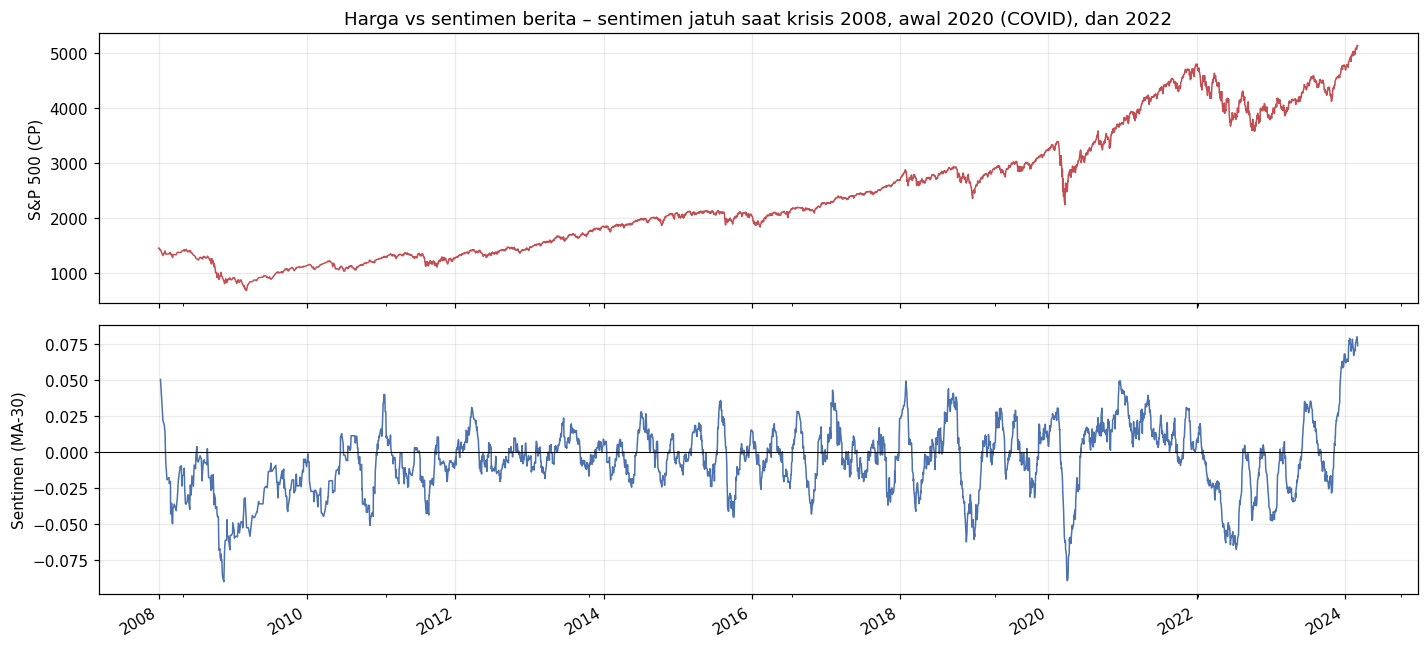

Korelasi fitur vs return BERIKUTNYA (kecil = wajar, pasar sulit diprediksi):
sent       -0.004
sent_ma3   -0.009
econ       -0.019
fin        -0.016
fear        0.005
trend      -0.052
vol         0.001
ret_1      -0.144

Korelasi sentimen vs return HARI YANG SAMA (headline sering merangkum pergerakan hari itu): 0.197


In [5]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
daily.set_index("Date").cp.plot(ax=ax[0], color="#C44E52", lw=1); ax[0].set_ylabel("S&P 500 (CP)")
daily.set_index("Date").sent.rolling(30, min_periods=5).mean().plot(ax=ax[1], color="#4C72B0", lw=1)
ax[1].axhline(0, color="k", lw=.7); ax[1].set_ylabel("Sentimen (MA-30)"); ax[1].set_xlabel("")
ax[0].set_title("Harga vs sentimen berita – sentimen jatuh saat krisis 2008, awal 2020 (COVID), dan 2022")
plt.tight_layout(); plt.savefig("figs/sentimen_vs_harga.png"); plt.show()

corr = daily[["sent","sent_ma3","econ","fin","fear","trend","vol","ret_1"]].corrwith(daily.ret_next).round(3)
print("Korelasi fitur vs return BERIKUTNYA (kecil = wajar, pasar sulit diprediksi):"); print(corr.to_string())
print("\nKorelasi sentimen vs return HARI YANG SAMA (headline sering merangkum pergerakan hari itu):",
      round(daily.sent.corr(daily.ret_1), 3))

## 4. Knowledge Base & Inference Engine

**Alur fakta → aturan → keputusan**
1. **Fakta numerik** (sentimen, tren harga, volatilitas, dll.) diubah menjadi **label linguistik** (fuzzifikasi sederhana): mis. `sentimen = very_neg`, `tren = oversold`.
2. **Forward chaining**: semua aturan `IF … THEN aksi (CF)` dievaluasi terhadap fakta.
3. **Certainty Factor (MYCIN)**: bila beberapa aturan mendukung aksi yang sama → `CF = CF₁ + CF₂ × (1 − CF₁)`.
4. **Conflict resolution**: aksi dengan CF tertinggi menang; BUY vs SELL harus unggul ≥ **0.15** dan CF ≥ **0.30**, jika tidak → **HOLD** (sinyal bertentangan = tunggu).

**Pembuatan aturan:** kombinasi (a) teori dari referensi, dan (b) statistik **data latih saja (≤2019)** – misalnya aturan “pasar tenang → HOLD” dan “sentimen sangat negatif + harga jatuh dalam → BUY (kontrarian)” terbukti lebih sering benar daripada peluang dasar di data latih, sedangkan aturan “ikuti momentum” justru **dibuang** karena data latih menunjukkan hasil lebih buruk dari acak.

In [6]:
# ---------- Fuzzifikasi: angka → label linguistik ----------
def level(x, vneg=-0.08, neg=-0.03, pos=0.03, vpos=0.08):
    return 'very_neg' if x<=vneg else 'neg' if x<=neg else 'very_pos' if x>=vpos else 'pos' if x>=pos else 'neutral'
def asp_level(x, t=0.05):   return 'neg' if x<=-t else 'pos' if x>=t else 'none'
def trend_level(x):         return 'oversold' if x<=-0.06 else 'down' if x<=-0.02 else 'overextended' if x>=0.05 else 'up' if x>=0.02 else 'flat'
def delta_level(x, t=0.02): return 'improving' if x>=t else 'deteriorating' if x<=-t else 'stable'
def vol_level(x):           return 'high' if x>=0.018 else 'low' if x<=0.006 else 'normal'
def fear_level(x):          return 'high' if x>=0.25 else 'none'

def fuzzify(f):
    return {'sent': level(f['sent_ma3']), 'delta': delta_level(f['sent_delta']), 'trend': trend_level(f['trend']),
            'vol': vol_level(f['vol']), 'fear': fear_level(f['fear']),
            'econ': asp_level(f['econ'], 0.03), 'fin': asp_level(f['fin'], 0.05), 'mon': asp_level(f['a_monetary'], 0.05),
            'infl': asp_level(f['a_inflation'], 0.05), 'unemp': asp_level(f['a_unemployment'], 0.05),
            'manuf': asp_level(f['a_manufacturing'], 0.05),
            'volume': 'low' if f['n'] <= 1 else 'high' if f['n'] >= 15 else 'normal'}

# ---------- KNOWLEDGE BASE: (id, nama, kondisi, aksi, CF, dasar) ----------
RULES = [
 ('R01','Pasar tenang',              lambda F: F['vol']=='low',                                                          'HOLD',0.55,'Volatility clustering: pasar tenang → pergerakan kecil (data latih ±67% HOLD)'),
 ('R02','Euforia + jenuh beli',      lambda F: F['sent']=='very_pos' and F['trend']=='overextended',                     'SELL',0.30,'Risiko bubble saat sentimen ekstrem (Maghyereh & Abdoh, 2022)'),
 ('R03','Pesimis + tren turun',      lambda F: F['sent'] in('neg','very_neg') and F['delta']=='deteriorating' and F['trend']=='down','SELL',0.35,'Sentimen memburuk sejalan dengan tren turun'),
 ('R04','Kontrarian oversold',       lambda F: F['sent'] in('neg','very_neg') and F['trend']=='oversold',                'BUY', 0.60,'Sentimen bearish ekstrem + harga jatuh dalam → peluang rebound'),
 ('R05','Panik mereda',              lambda F: F['fear']=='high' and F['delta']=='improving',                            'BUY', 0.40,'Kata krisis/crash banyak namun sentimen mulai membaik'),
 ('R06','Volatilitas tinggi + turun',lambda F: F['vol']=='high' and F['trend'] in('down','oversold'),                    'BUY', 0.45,'Capitulation / mean reversion jangka pendek (data latih ±50% BUY)'),
 ('R07','Resesi ganda',              lambda F: F['econ']=='neg' and F['fin']=='neg',                                     'SELL',0.55,'Sentimen ekonomi & sektor keuangan sama-sama negatif (Barbaglia et al., 2022)'),
 ('R08','Pelonggaran moneter',       lambda F: F['mon']=='pos' and F['trend']!='overextended',                           'BUY', 0.40,'Kebijakan longgar mendorong aset berisiko (Maghyereh & Abdoh, 2022)'),
 ('R09','Inflasi + suku bunga naik', lambda F: F['infl']=='neg' and F['mon']=='neg',                                     'SELL',0.40,'Tekanan inflasi & pengetatan moneter'),
 ('R10','Ekonomi & manufaktur +',    lambda F: F['econ']=='pos' and F['manuf']=='pos',                                   'BUY', 0.45,'Sinyal ekspansi sektor riil (Barbaglia et al., 2022)'),
 ('R11','Tenaga kerja negatif',      lambda F: F['unemp']=='neg' and F['sent'] in('neg','very_neg','neutral'),           'SELL',0.55,'PHK/pengangguran naik → indikasi pelemahan ekonomi'),
 ('R12','Netral & datar',            lambda F: F['sent']=='neutral' and F['trend']=='flat',                              'HOLD',0.45,'Tidak ada sinyal kuat'),
 ('R13','Sentimen sangat negatif',   lambda F: F['sent']=='very_neg',                                                    'BUY', 0.35,'Kontrarian: pesimisme ekstrem sering diikuti pemulihan'),
 ('R14','Tren naik stabil',          lambda F: F['trend']=='up' and F['vol']!='high',                                    'HOLD',0.50,'Tren naik berjalan pelan (data latih ±67% HOLD)'),
 ('R15','Optimis + tren naik',       lambda F: F['sent'] in('pos','very_pos') and F['trend'] in('up','overextended'),    'HOLD',0.45,'Tidak ada keunggulan mengejar momentum (data latih ±64% HOLD)'),
 ('R16','Berita sedikit',            lambda F: F['volume']=='low' and F['sent']=='neutral',                              'HOLD',0.25,'Informasi tidak memadai'),
]
MIN_CF, MIN_MARGIN = 0.30, 0.15

def infer(F):
    """Forward chaining + kombinasi Certainty Factor. Return (keputusan, cf_per_aksi, aturan_aktif)."""
    cf, fired = {'BUY':0.0, 'SELL':0.0, 'HOLD':0.0}, []
    for rid, name, cond, act, c, src in RULES:
        if cond(F):
            cf[act] = cf[act] + c*(1-cf[act]); fired.append((rid, name, act, c))
    best = max(cf, key=cf.get)
    if best in ('BUY','SELL'):
        other = 'SELL' if best == 'BUY' else 'BUY'
        if cf[best] < MIN_CF or cf[best]-cf[other] < MIN_MARGIN: best = 'HOLD'      # konflik / lemah → tunggu
    elif cf['HOLD'] < MIN_CF: best = 'HOLD'
    return best, cf, fired

kb_table = pd.DataFrame([{"ID": r[0], "Nama": r[1], "Aksi": r[3], "CF": r[4], "Dasar / sumber": r[5]} for r in RULES])
kb_table

,ID,Nama,Aksi,CF,Dasar / sumber
0,R01,Pasar tenang,HOLD,0.55,Volatility clustering: pasar tenang → pergerakan kecil (data latih ±67% HOLD)
1,R02,Euforia + jenuh beli,SELL,0.30,"Risiko bubble saat sentimen ekstrem (Maghyereh & Abdoh, 2022)"
2,R03,Pesimis + tren turun,SELL,0.35,Sentimen memburuk sejalan dengan tren turun
3,R04,Kontrarian oversold,BUY,0.60,Sentimen bearish ekstrem + harga jatuh dalam → peluang rebound
4,R05,Panik mereda,BUY,0.40,Kata krisis/crash banyak namun sentimen mulai membaik
5,R06,Volatilitas tinggi + turun,BUY,0.45,Capitulation / mean reversion jangka pendek (data latih ±50% BUY)
6,R07,Resesi ganda,SELL,0.55,"Sentimen ekonomi & sektor keuangan sama-sama negatif (Barbaglia et al., 2022)"
7,R08,Pelonggaran moneter,BUY,0.40,"Kebijakan longgar mendorong aset berisiko (Maghyereh & Abdoh, 2022)"
8,R09,Inflasi + suku bunga naik,SELL,0.40,Tekanan inflasi & pengetatan moneter
9,R10,Ekonomi & manufaktur +,BUY,0.45,"Sinyal ekspansi sektor riil (Barbaglia et al., 2022)"


### 4.1 Knowledge base dalam bentuk IF–THEN (untuk laporan)

In [7]:
IF_TEXT = {
 'R01':"IF volatilitas = rendah",
 'R02':"IF sentimen = sangat positif AND harga = jenuh beli (>5% di atas MA20)",
 'R03':"IF sentimen ∈ {negatif, sangat negatif} AND sentimen memburuk AND tren = turun",
 'R04':"IF sentimen ∈ {negatif, sangat negatif} AND harga = oversold (<-6% dari MA20)",
 'R05':"IF proporsi headline 'panik' tinggi AND sentimen membaik",
 'R06':"IF volatilitas = tinggi AND tren ∈ {turun, oversold}",
 'R07':"IF sentimen ekonomi = negatif AND sentimen sektor keuangan = negatif",
 'R08':"IF sentimen kebijakan moneter = positif AND harga tidak jenuh beli",
 'R09':"IF sentimen inflasi = negatif AND sentimen moneter = negatif",
 'R10':"IF sentimen ekonomi = positif AND sentimen manufaktur = positif",
 'R11':"IF sentimen tenaga kerja = negatif AND sentimen umum ∈ {negatif, sangat negatif, netral}",
 'R12':"IF sentimen = netral AND tren = datar",
 'R13':"IF sentimen = sangat negatif",
 'R14':"IF tren = naik AND volatilitas ≠ tinggi",
 'R15':"IF sentimen ∈ {positif, sangat positif} AND tren ∈ {naik, jenuh beli}",
 'R16':"IF jumlah berita ≤ 1 AND sentimen = netral",
}
for r in RULES:
    print(f"{r[0]}  {IF_TEXT[r[0]]}\n     THEN {r[3]}  (CF = {r[4]})   # {r[1]}")

R01  IF volatilitas = rendah
     THEN HOLD  (CF = 0.55)   # Pasar tenang
R02  IF sentimen = sangat positif AND harga = jenuh beli (>5% di atas MA20)
     THEN SELL  (CF = 0.3)   # Euforia + jenuh beli
R03  IF sentimen ∈ {negatif, sangat negatif} AND sentimen memburuk AND tren = turun
     THEN SELL  (CF = 0.35)   # Pesimis + tren turun
R04  IF sentimen ∈ {negatif, sangat negatif} AND harga = oversold (<-6% dari MA20)
     THEN BUY  (CF = 0.6)   # Kontrarian oversold
R05  IF proporsi headline 'panik' tinggi AND sentimen membaik
     THEN BUY  (CF = 0.4)   # Panik mereda
R06  IF volatilitas = tinggi AND tren ∈ {turun, oversold}
     THEN BUY  (CF = 0.45)   # Volatilitas tinggi + turun
R07  IF sentimen ekonomi = negatif AND sentimen sektor keuangan = negatif
     THEN SELL  (CF = 0.55)   # Resesi ganda
R08  IF sentimen kebijakan moneter = positif AND harga tidak jenuh beli
     THEN BUY  (CF = 0.4)   # Pelonggaran moneter
R09  IF sentimen inflasi = negatif AND sentimen moneter = negatif


## 5. Diagram Sistem (untuk laporan)
### 5.1 Arsitektur sistem

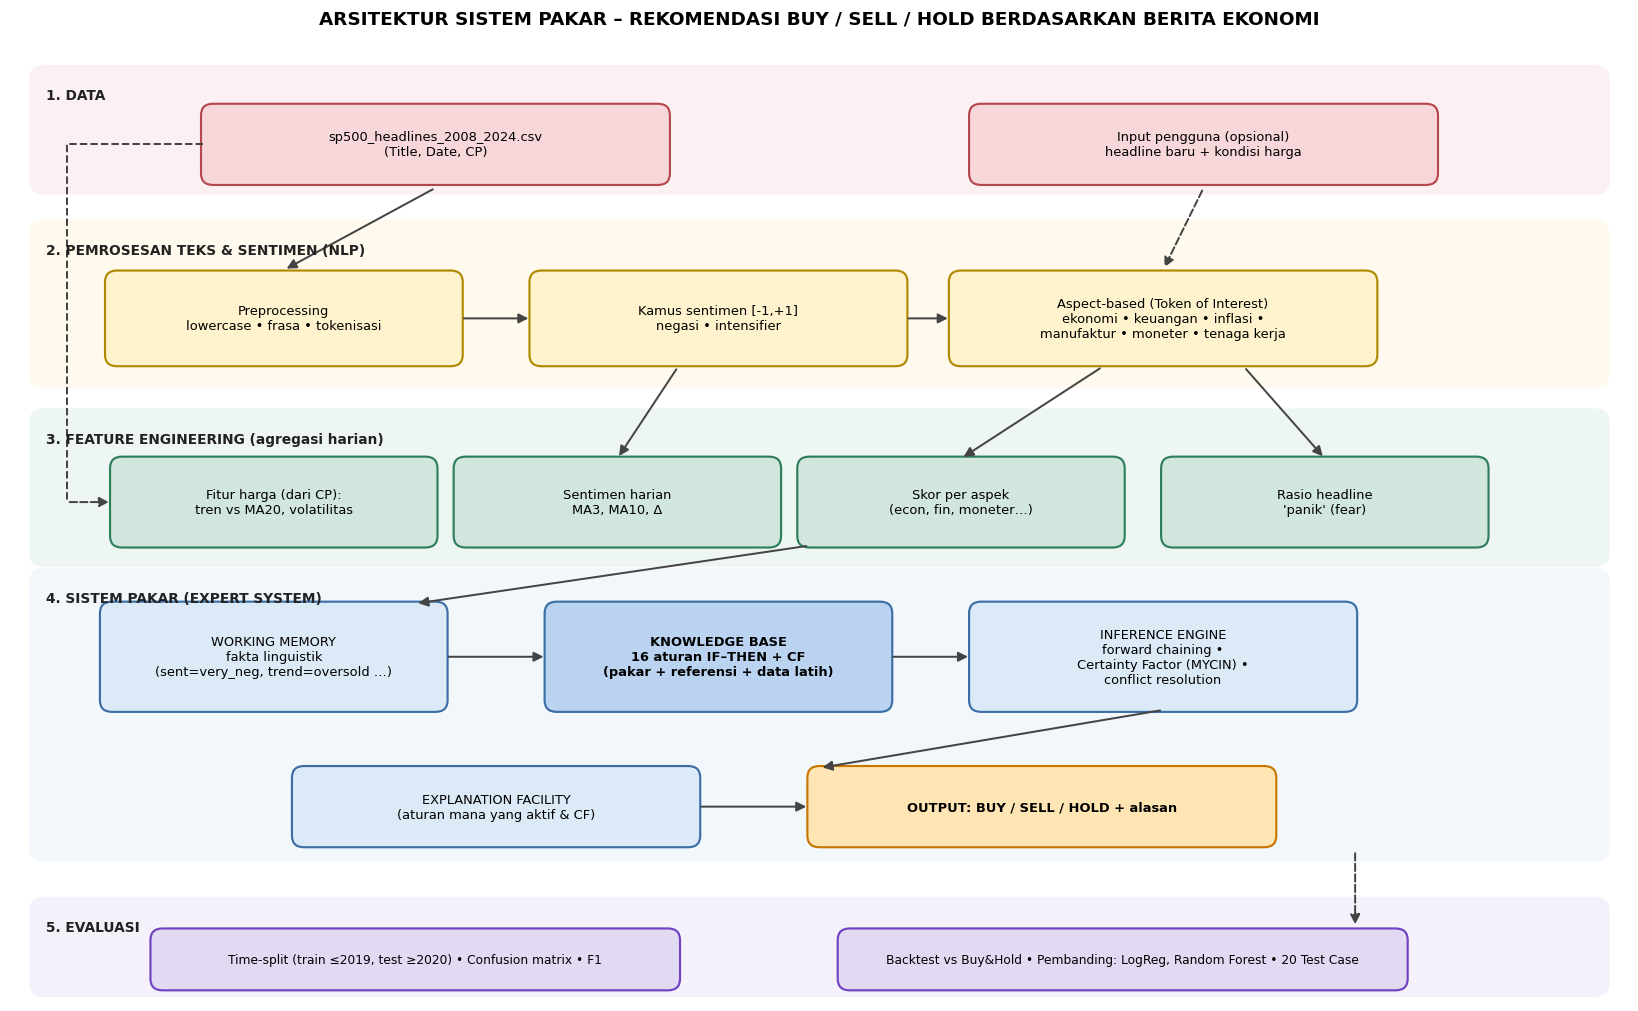

In [8]:
def _box(ax, x, y, w, h, text, fc="#DCE9F7", ec="#3B6EA5", fs=8.5, bold=False):
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec=ec, lw=1.4))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal", wrap=True)
def _arrow(ax, x1, y1, x2, y2, label=None, color="#444", ls="-"):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=13, color=color, lw=1.3, linestyle=ls))
    if label: ax.text((x1+x2)/2+0.08, (y1+y2)/2+0.08, label, fontsize=8, color=color, ha="left")
def _layer(ax, y, h, title, color):
    ax.add_patch(FancyBboxPatch((0.2, y-h/2), 15.6, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=color, ec="none", alpha=.35))
    ax.text(0.35, y+h/2-0.22, title, fontsize=9, fontweight="bold", color="#222", va="top")

def draw_architecture(path="figs/arsitektur_sistem.png"):
    fig, ax = plt.subplots(figsize=(15, 9.3)); ax.set_xlim(0, 16); ax.set_ylim(0, 10); ax.axis("off"); ax.grid(False)
    ax.set_title("ARSITEKTUR SISTEM PAKAR – REKOMENDASI BUY / SELL / HOLD BERDASARKAN BERITA EKONOMI", fontsize=12, fontweight="bold")
    _layer(ax, 9.0, 1.3, "1. DATA", "#F8D7DA");            _box(ax, 4.2, 8.85, 4.6, .8, "sp500_headlines_2008_2024.csv\n(Title, Date, CP)", "#F8D7DA", "#B5474E")
    _box(ax, 11.8, 8.85, 4.6, .8, "Input pengguna (opsional)\nheadline baru + kondisi harga", "#F8D7DA", "#B5474E")
    _layer(ax, 7.2, 1.7, "2. PEMROSESAN TEKS & SENTIMEN (NLP)", "#FFF3CD")
    _box(ax, 2.7, 7.05, 3.5, .95, "Preprocessing\nlowercase • frasa • tokenisasi", "#FFF3CD", "#B08900")
    _box(ax, 7.0, 7.05, 3.7, .95, "Kamus sentimen [-1,+1]\nnegasi • intensifier", "#FFF3CD", "#B08900")
    _box(ax, 11.4, 7.05, 4.2, .95, "Aspect-based (Token of Interest)\nekonomi • keuangan • inflasi •\nmanufaktur • moneter • tenaga kerja", "#FFF3CD", "#B08900")
    _layer(ax, 5.3, 1.6, "3. FEATURE ENGINEERING (agregasi harian)", "#D1E7DD")
    for x, t in [(2.6, "Fitur harga (dari CP):\ntren vs MA20, volatilitas"), (6.0, "Sentimen harian\nMA3, MA10, Δ"), (9.4, "Skor per aspek\n(econ, fin, moneter…)"), (13.0, "Rasio headline\n'panik' (fear)")]:
        _box(ax, x, 5.15, 3.2, .9, t, "#D1E7DD", "#2E7D5B")
    _layer(ax, 2.95, 3.0, "4. SISTEM PAKAR (EXPERT SYSTEM)", "#DCE9F7")
    _box(ax, 2.6, 3.55, 3.4, 1.1, "WORKING MEMORY\nfakta linguistik\n(sent=very_neg, trend=oversold …)", "#DCE9F7", "#3B6EA5", bold=False)
    _box(ax, 7.0, 3.55, 3.4, 1.1, "KNOWLEDGE BASE\n16 aturan IF–THEN + CF\n(pakar + referensi + data latih)", "#B9D3F0", "#3B6EA5", bold=True)
    _box(ax, 11.4, 3.55, 3.8, 1.1, "INFERENCE ENGINE\nforward chaining •\nCertainty Factor (MYCIN) •\nconflict resolution", "#DCE9F7", "#3B6EA5")
    _box(ax, 4.8, 2.0, 4.0, .8, "EXPLANATION FACILITY\n(aturan mana yang aktif & CF)", "#DCE9F7", "#3B6EA5")
    _box(ax, 10.2, 2.0, 4.6, .8, "OUTPUT: BUY / SELL / HOLD + alasan", "#FFE5B4", "#C77700", bold=True)
    _layer(ax, 0.55, 1.0, "5. EVALUASI", "#E2D9F3")
    _box(ax, 4.0, 0.42, 5.2, .6, "Time-split (train ≤2019, test ≥2020) • Confusion matrix • F1", "#E2D9F3", "#6F42C1", fs=8)
    _box(ax, 11.0, 0.42, 5.6, .6, "Backtest vs Buy&Hold • Pembanding: LogReg, Random Forest • 20 Test Case", "#E2D9F3", "#6F42C1", fs=8)
    _arrow(ax, 4.2, 8.4, 2.7, 7.55)                       # CSV → preprocessing
    _arrow(ax, 11.8, 8.4, 11.4, 7.55, ls="--")             # input pengguna → NLP
    ax.plot([1.9, 0.55, 0.55], [8.85, 8.85, 5.15], color="#444", lw=1.3, ls="--"); _arrow(ax, 0.55, 5.15, 1.0, 5.15, color="#444", ls="--")  # kolom CP
    _arrow(ax, 4.45, 7.05, 5.15, 7.05); _arrow(ax, 8.85, 7.05, 9.3, 7.05)
    _arrow(ax, 6.6, 6.55, 6.0, 5.6); _arrow(ax, 10.8, 6.55, 9.4, 5.6); _arrow(ax, 12.2, 6.55, 13.0, 5.6)
    _arrow(ax, 7.9, 4.7, 4.0, 4.1)                         # fitur → working memory
    _arrow(ax, 4.3, 3.55, 5.3, 3.55); _arrow(ax, 8.7, 3.55, 9.5, 3.55)
    _arrow(ax, 11.4, 3.0, 8.0, 2.4); _arrow(ax, 6.8, 2.0, 7.9, 2.0)
    _arrow(ax, 13.3, 1.55, 13.3, 0.75, ls="--")
    plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.show()

draw_architecture()

### 5.2 Flowchart program

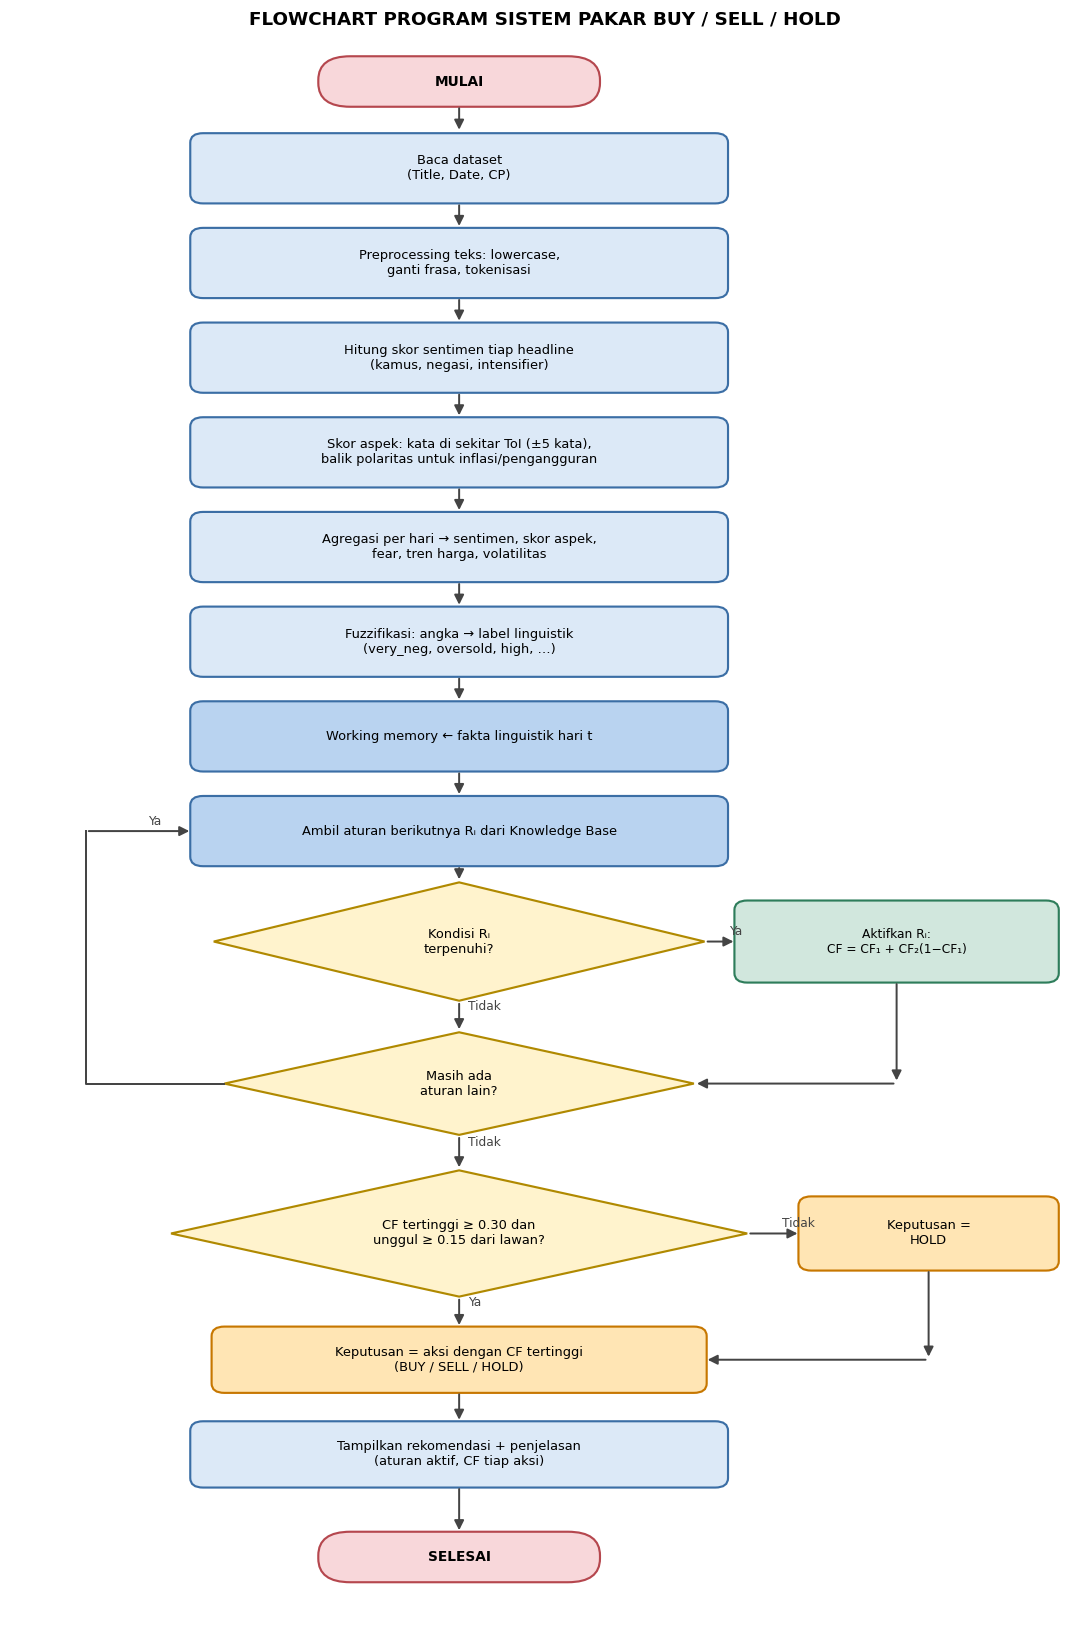

In [9]:
def _diamond(ax, x, y, w, h, text, fc="#FFF3CD", ec="#B08900", fs=8.5):
    ax.add_patch(Polygon([(x, y+h/2), (x+w/2, y), (x, y-h/2), (x-w/2, y)], closed=True, fc=fc, ec=ec, lw=1.4))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs)
def _term(ax, x, y, text, w=2.6, h=.6):
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.3", fc="#F8D7DA", ec="#B5474E", lw=1.4))
    ax.text(x, y, text, ha="center", va="center", fontsize=9, fontweight="bold")

def draw_flowchart(path="figs/flowchart.png"):
    fig, ax = plt.subplots(figsize=(10, 15)); ax.set_xlim(0, 10); ax.set_ylim(0, 20.2); ax.axis("off"); ax.grid(False)
    ax.set_title("FLOWCHART PROGRAM SISTEM PAKAR BUY / SELL / HOLD", fontsize=12, fontweight="bold")
    X = 4.2
    _term(ax, X, 19.6, "MULAI")
    steps = [(18.5, "Baca dataset\n(Title, Date, CP)"),
             (17.3, "Preprocessing teks: lowercase,\nganti frasa, tokenisasi"),
             (16.1, "Hitung skor sentimen tiap headline\n(kamus, negasi, intensifier)"),
             (14.9, "Skor aspek: kata di sekitar ToI (±5 kata),\nbalik polaritas untuk inflasi/pengangguran"),
             (13.7, "Agregasi per hari → sentimen, skor aspek,\nfear, tren harga, volatilitas"),
             (12.5, "Fuzzifikasi: angka → label linguistik\n(very_neg, oversold, high, …)")]
    for y, t in steps: _box(ax, X, y, 5.0, .85, t, fs=8.5)
    _arrow(ax, X, 19.3, X, 18.95)
    ys = [18.5, 17.3, 16.1, 14.9, 13.7, 12.5]
    for a, b in zip(ys[:-1], ys[1:]): _arrow(ax, X, a-.43, X, b+.43)
    _box(ax, X, 11.3, 5.0, .85, "Working memory ← fakta linguistik hari t", "#B9D3F0", "#3B6EA5", fs=8.5); _arrow(ax, X, 12.07, X, 11.73)
    _box(ax, X, 10.1, 5.0, .85, "Ambil aturan berikutnya Rᵢ dari Knowledge Base", "#B9D3F0", "#3B6EA5", fs=8.5); _arrow(ax, X, 10.87, X, 10.53)
    _diamond(ax, X, 8.7, 4.6, 1.5, "Kondisi Rᵢ\nterpenuhi?"); _arrow(ax, X, 9.67, X, 9.45)
    _box(ax, 8.3, 8.7, 3.0, 1.0, "Aktifkan Rᵢ:\nCF = CF₁ + CF₂(1−CF₁)", "#D1E7DD", "#2E7D5B", fs=8); _arrow(ax, X+2.3, 8.7, 6.8, 8.7, "Ya")
    _diamond(ax, X, 6.9, 4.4, 1.3, "Masih ada\naturan lain?"); _arrow(ax, X, 7.95, X, 7.55, "Tidak")
    _arrow(ax, 8.3, 8.2, 8.3, 6.9); _arrow(ax, 8.3, 6.9, X+2.2, 6.9)
    ax.plot([X-2.2, 0.7, 0.7], [6.9, 6.9, 10.1], color="#444", lw=1.3); _arrow(ax, 0.7, 10.1, X-2.5, 10.1, "Ya")
    _diamond(ax, X, 5.0, 5.4, 1.6, "CF tertinggi ≥ 0.30 dan\nunggul ≥ 0.15 dari lawan?"); _arrow(ax, X, 6.25, X, 5.8, "Tidak")
    _box(ax, X, 3.4, 4.6, .8, "Keputusan = aksi dengan CF tertinggi\n(BUY / SELL / HOLD)", "#FFE5B4", "#C77700", fs=8.5); _arrow(ax, X, 4.2, X, 3.8, "Ya")
    _box(ax, 8.6, 5.0, 2.4, .9, "Keputusan =\nHOLD", "#FFE5B4", "#C77700", fs=8.5); _arrow(ax, X+2.7, 5.0, 7.4, 5.0, "Tidak")
    _arrow(ax, 8.6, 4.55, 8.6, 3.4); _arrow(ax, 8.6, 3.4, X+2.3, 3.4)
    _box(ax, X, 2.2, 5.0, .8, "Tampilkan rekomendasi + penjelasan\n(aturan aktif, CF tiap aksi)", "#DCE9F7", "#3B6EA5", fs=8.5); _arrow(ax, X, 3.0, X, 2.6)
    _term(ax, X, 0.9, "SELESAI"); _arrow(ax, X, 1.8, X, 1.2)
    plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.show()

draw_flowchart()

## 6. Evaluasi pada Data Historis
**Skema:** pembagian **berdasarkan waktu** (bukan acak, agar tidak ada kebocoran masa depan):
- **Train** : ≤ 31-12-2019 (dipakai untuk menentukan/menguji aturan)
- **Test**  : ≥ 01-01-2020 (mencakup COVID-19, inflasi 2022, rally AI 2023)

Metrik (mengikuti survei referensi ke-3): accuracy, precision, recall, F1, confusion matrix.

[TRAIN]  n=2451  accuracy=0.535  macro-F1=0.318   | baseline 'selalu HOLD': 0.516
[TEST]  n=1035  accuracy=0.397  macro-F1=0.276   | baseline 'selalu HOLD': 0.399

               precision    recall  f1-score   support

         BUY      0.404     0.123     0.189       341
        HOLD      0.406     0.857     0.551       413
        SELL      0.254     0.053     0.088       281

    accuracy                          0.397      1035
   macro avg      0.355     0.345     0.276      1035
weighted avg      0.364     0.397     0.306      1035



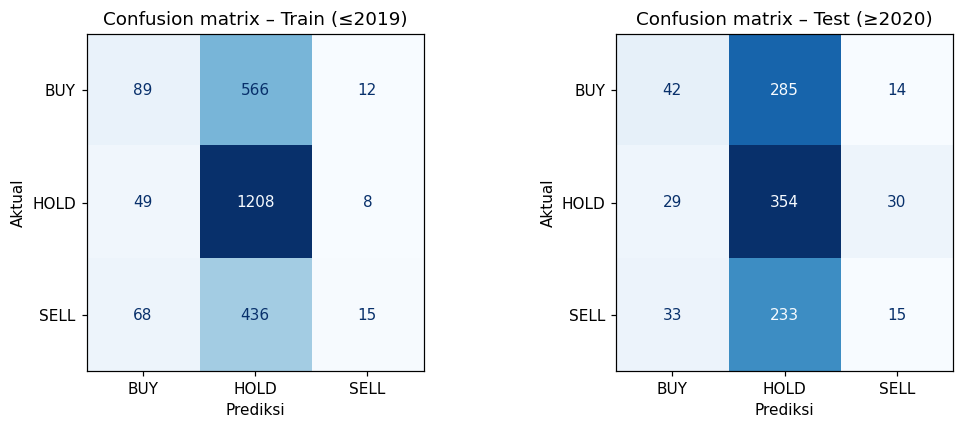

In [10]:
def run_es(x):
    out = [infer(fuzzify(r)) for _, r in x.iterrows()]
    return [o[0] for o in out], [o[1] for o in out], [o[2] for o in out]

train = data[data.Date <  "2020-01-01"].copy()
test  = data[data.Date >= "2020-01-01"].copy()
train["pred"], _, _         = run_es(train)
test["pred"], test_cf, test_fired = run_es(test)
LABELS = ["BUY", "HOLD", "SELL"]
maj = train.label.mode()[0]

def report(x, name):
    acc = accuracy_score(x.label, x.pred)
    p, r, f, _ = precision_recall_fscore_support(x.label, x.pred, labels=LABELS, zero_division=0)
    print(f"[{name}]  n={len(x)}  accuracy={acc:.3f}  macro-F1={f.mean():.3f}   | baseline 'selalu {maj}': {(x.label==maj).mean():.3f}")
    return acc

report(train, "TRAIN"); report(test, "TEST")
print("\n", classification_report(test.label, test.pred, labels=LABELS, digits=3, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, x, nm in zip(ax, [train, test], ["Train (≤2019)", "Test (≥2020)"]):
    ConfusionMatrixDisplay(confusion_matrix(x.label, x.pred, labels=LABELS), display_labels=LABELS).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"Confusion matrix – {nm}"); a.grid(False); a.set_xlabel("Prediksi"); a.set_ylabel("Aktual")
plt.tight_layout(); plt.savefig("figs/confusion.png"); plt.show()

### 6.1 Pembanding: model Machine Learning pada fitur yang sama
Untuk melihat apakah sistem pakar masuk akal dibanding model *black box* (seperti pendekatan ML pada survei referensi ke-3).

,Model,Accuracy,Macro-F1
0,Baseline: selalu HOLD,0.399,0.190
1,Sistem Pakar (rule-based CF),0.397,0.276
2,Logistic Regression,0.443,0.312
3,Random Forest,0.453,0.324


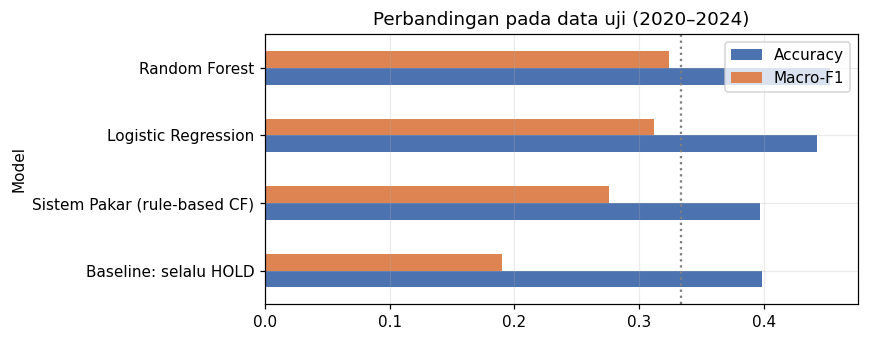

In [11]:
FEATS = ["sent_ma3","sent_delta","econ","fin","fear","trend","vol","n","a_market","a_monetary","a_inflation","a_unemployment","a_manufacturing"]
Xtr, Xte = train[FEATS], test[FEATS]

models = {
  "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
  "Random Forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=15, random_state=42, n_jobs=-1),
}
rows = [{"Model":"Baseline: selalu "+maj, "Accuracy":(test.label==maj).mean(), "Macro-F1":precision_recall_fscore_support(test.label,[maj]*len(test),labels=LABELS,zero_division=0)[2].mean()},
        {"Model":"Sistem Pakar (rule-based CF)", "Accuracy":accuracy_score(test.label,test.pred), "Macro-F1":precision_recall_fscore_support(test.label,test.pred,labels=LABELS,zero_division=0)[2].mean()}]
for nm, m in models.items():
    m.fit(Xtr, train.label); p = m.predict(Xte); test["pred_"+nm[:2]] = p
    rows.append({"Model":nm, "Accuracy":accuracy_score(test.label,p), "Macro-F1":precision_recall_fscore_support(test.label,p,labels=LABELS,zero_division=0)[2].mean()})
cmp_df = pd.DataFrame(rows).round(3); display(cmp_df)
ax = cmp_df.set_index("Model")[["Accuracy","Macro-F1"]].plot.barh(figsize=(8, 3.2), color=["#4C72B0","#DD8452"]); ax.set_title("Perbandingan pada data uji (2020–2024)")
ax.axvline(1/3, color="gray", ls=":"); plt.tight_layout(); plt.savefig("figs/perbandingan_model.png"); plt.show()

### 6.2 Seberapa baik sinyal BUY / SELL? (precision sinyal & backtest sederhana)
Karena sistem sengaja konservatif (banyak HOLD), yang lebih relevan adalah **ketika sistem mengatakan BUY/SELL, seberapa sering benar** dibanding peluang dasar.
Backtest: BUY = posisi long, SELL = posisi short, HOLD = tidak trading, dihitung terhadap `ret_next`. **Tanpa biaya transaksi.**

,Sinyal,Jumlah,Precision sinyal,Peluang dasar,Rata-rata return berikutnya
0,BUY,104,0.4038,0.3295,0.0021
1,SELL,59,0.2542,0.2715,-0.0012


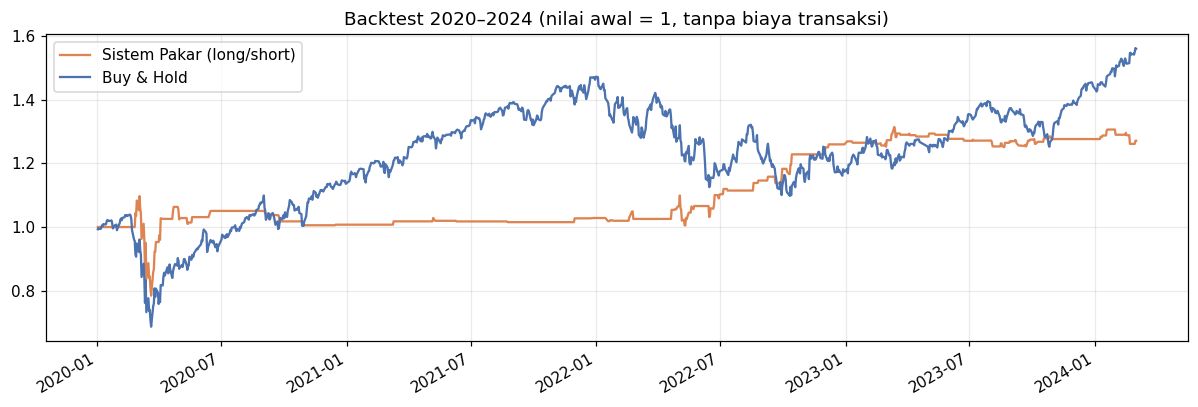

Return kumulatif  Sistem Pakar: +27.1%   |   Buy&Hold: +56.1%
Jumlah transaksi aktif: 163 dari 1035 hari


In [12]:
base = test.label.value_counts(normalize=True)
sig = []
for a in ["BUY","SELL"]:
    m = test.pred == a
    sig.append({"Sinyal": a, "Jumlah": int(m.sum()), "Precision sinyal": (test.label[m]==a).mean() if m.sum() else np.nan,
                "Peluang dasar": base[a], "Rata-rata return berikutnya": test.ret_next[m].mean() if m.sum() else np.nan})
display(pd.DataFrame(sig).round(4))

pos = test.pred.map({"BUY": 1, "SELL": -1, "HOLD": 0})
strat = (pos*test.ret_next).fillna(0)
bh    = test.ret_next.fillna(0)
eq = pd.DataFrame({"Sistem Pakar (long/short)": (1+strat).cumprod(), "Buy & Hold": (1+bh).cumprod()}); eq.index = test.Date.values
ax = eq.plot(figsize=(11, 3.8), color=["#DD8452","#4C72B0"]); ax.set_title("Backtest 2020–2024 (nilai awal = 1, tanpa biaya transaksi)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("figs/backtest.png"); plt.show()
print(f"Return kumulatif  Sistem Pakar: {eq.iloc[-1,0]-1:+.1%}   |   Buy&Hold: {eq.iloc[-1,1]-1:+.1%}")
print(f"Jumlah transaksi aktif: {(pos!=0).sum()} dari {len(test)} hari")

### 6.3 Aturan mana yang paling sering aktif?

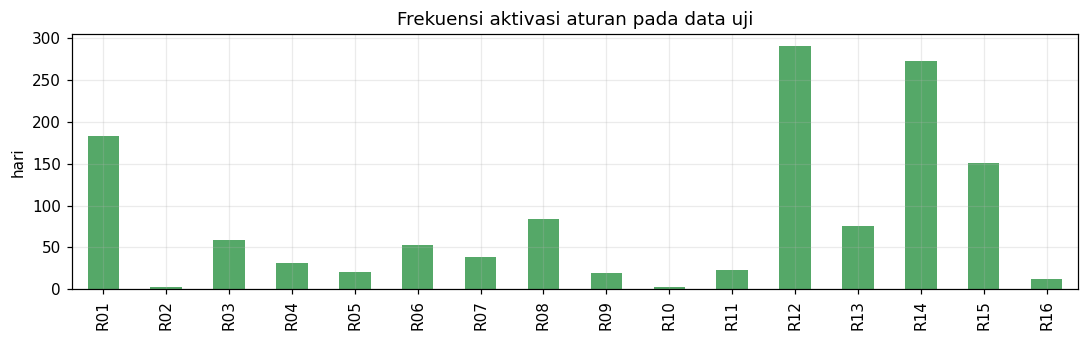

In [13]:
from collections import Counter
cnt = Counter(r[0] for f in test_fired for r in f)
freq = pd.Series(cnt).reindex([r[0] for r in RULES]).fillna(0).astype(int)
ax = freq.plot.bar(figsize=(10, 3.2), color="#55A868"); ax.set_title("Frekuensi aktivasi aturan pada data uji"); ax.set_ylabel("hari")
plt.tight_layout(); plt.savefig("figs/frekuensi_aturan.png"); plt.show()

## 7. Test Case (minimum 20)
Setiap kasus = **skenario berita + kondisi harga** dengan **hasil yang diharapkan** (ditentukan dari desain knowledge base/logika pakar). Kasus ini berfungsi sebagai *regression test* untuk memastikan sistem berperilaku sesuai desain, bukan untuk mengukur akurasi prediksi pasar.

Untuk realisme, tiap skenario ditambah 3 headline netral (satu hari nyata memuat banyak headline tanpa sentimen kuat).

In [14]:
FILLER = ["Investors watch earnings calendar this week", "Trading volume steady in afternoon session", "Analysts review quarterly reports"]

def make_facts(headlines, trend=0.0, vol=0.01, prev_sent=0.0, filler=True):
    """Bangun fakta numerik dari daftar headline + kondisi harga (trend vs MA20, volatilitas, rata-rata sentimen sebelumnya)."""
    hs = list(headlines) + (FILLER if (filler and headlines) else [])
    ov, asp, fear = [], {a: [] for a in ASPECTS}, 0
    for t in hs:
        o, a = headline_sentiment(t); ov.append(o)
        for k, v in a.items(): asp[k].append(v)
        if any(LEXICON.get(w, 0) <= -.7 for w in preprocess(t)): fear += 1
    m = lambda v: float(np.mean(v)) if v else 0.0
    s = m(ov)
    f = {'n': len(hs), 'sent_ma3': s, 'sent_delta': s-prev_sent, 'trend': trend, 'vol': vol, 'fear': fear/len(hs) if hs else 0.0}
    for k, v in asp.items(): f['a_'+k] = m(v)
    f['econ'] = float(np.mean([f['a_economy'], f['a_unemployment'], f['a_manufacturing'], f['a_inflation']]))
    f['fin']  = float(np.mean([f['a_financial'], f['a_monetary']]))
    return f

def advise(headlines, trend=0.0, vol=0.01, prev_sent=0.0, verbose=True):
    """Fungsi utama: headline + kondisi harga → rekomendasi + penjelasan."""
    f = make_facts(headlines, trend, vol, prev_sent); F = fuzzify(f); dec, cf, fired = infer(F)
    if verbose:
        print("="*70); print("Headline :", *(headlines or ["(tidak ada)"]), sep="\n   • ")
        print(f"Kondisi  : tren vs MA20 = {trend:+.1%}, volatilitas = {vol:.3f}, sentimen sebelumnya = {prev_sent:+.2f}")
        print("Fakta    :", F)
        print("Aturan aktif:"); [print(f"   {r[0]} {r[1]:<28} → {r[2]:<4} (CF {r[3]})") for r in fired] or print("   (tidak ada)")
        print("CF total :", {k: round(v, 2) for k, v in cf.items()})
        print(f"\n>>> REKOMENDASI: {dec}")
    return dec, cf, fired, F

# (id, deskripsi, headline, trend, vol, prev_sent, ekspektasi, alasan)
TEST_CASES = [
 ("TC01","Pasar tenang, berita netral",                ["Stocks little changed ahead of jobs data"],                                              0.00, 0.004,  0.00,"HOLD","R01 pasar tenang"),
 ("TC02","Panik + harga jatuh dalam (oversold)",       ["Stocks plunge as fears of recession grow","Wall Street tumbles on worst selloff in months"],-0.09, 0.020,  0.00,"BUY", "R04/R06 kontrarian"),
 ("TC03","Ekonomi & sektor keuangan sama-sama negatif",["Economy shrinks as banks report heavy losses","Bank lending falls sharply, economic growth slows"],-0.01,0.012, 0.00,"SELL","R07 resesi ganda"),
 ("TC04","Bank sentral menurunkan suku bunga",         ["Fed cuts rates to boost economy","Central bank easing lifts stocks"],                    0.01, 0.010,  0.00,"BUY", "R08 pelonggaran moneter"),
 ("TC05","Inflasi tinggi + kenaikan suku bunga",       ["Inflation is not easing as Fed hikes rates","Rising prices force central bank to raise rates"],0.00,0.010, 0.00,"SELL","R09 inflasi+bunga"),
 ("TC06","Ekonomi & manufaktur kuat",                  ["Economy grows strongly as manufacturing output rises","Factory production jumps, economic growth robust"],0.01,0.010,0.00,"BUY","R10 ekspansi riil"),
 ("TC07","PHK massal & pengangguran naik",             ["Layoffs surge as unemployment rises","Job losses mount, jobless claims jump"],           -0.01, 0.010,  0.00,"SELL","R11 tenaga kerja negatif"),
 ("TC08","Euforia, harga jenuh beli → jangan mengejar",["Stocks soar to record high as bulls cheer","Markets surge on booming profits"],              0.07, 0.012,  0.00,"HOLD","R15 (>R02) tidak kejar momentum"),
 ("TC09","Tidak ada berita sama sekali",               [],                                                                                       0.00, 0.010,  0.00,"HOLD","R12/R16 informasi kurang"),
 ("TC10","Panik mereda setelah crash",                 ["Stocks rebound as fears ease after crash","Panic subsides, markets recover"],            -0.03, 0.015, -0.15,"BUY", "R05 panik mereda"),
 ("TC11","Volatilitas tinggi & tren turun",            ["Stocks swing wildly as investors weigh data"],                                           -0.03, 0.022,  0.00,"BUY", "R06 capitulation"),
 ("TC12","Tren naik tenang, sentimen positif",         ["Stocks edge higher"],                                                                    0.03, 0.005,  0.00,"HOLD","R01/R14/R15"),
 ("TC13","Sentimen positif, harga datar (tanpa aturan cocok)",["Stocks gain on upbeat earnings"],                                                 0.00, 0.010,  0.00,"HOLD","default HOLD"),
 ("TC14","Crash headline, harga belum turun dalam",    ["Stocks crash in worst rout since 2008","Panic selling wipes out trillions"],             -0.01, 0.015,  0.00,"BUY", "R13 kontrarian"),
 ("TC15","Sinyal bertentangan (R03 SELL vs R13 BUY)",  ["Stocks slide as worries grow","Wall Street falls on weak data"],                         -0.03, 0.012,  0.02,"HOLD","conflict resolution → HOLD"),
 ("TC16","Pelonggaran moneter tapi harga jenuh beli",  ["Fed cuts rates as economy weakens"],                                                      0.06, 0.010,  0.00,"HOLD","R08 diblokir jenuh beli"),
 ("TC17","Krisis keuangan + resesi",                   ["Economy slips into recession as banks fail","Financial crisis deepens, economic outlook grim"],-0.01,0.012,0.00,"SELL","R07 unggul atas R13"),
 ("TC18","Rally berita bagus, tren naik",              ["Wall Street rallies on strong jobs report","Stocks climb as hopes rise for more stimulus"],0.02,0.011,-0.02,"HOLD","R14/R15 tidak kejar momentum"),
 ("TC19","Pesimis ringan, memburuk, tren turun",       ["Dow drops as investors worry about slowing growth"],                                     -0.025,0.014,  0.03,"SELL","R03 pesimis + tren turun"),
 ("TC20","Berita campur, menunggu keputusan Fed",      ["Stocks mixed as investors await Fed decision","Markets quiet before earnings"],           0.00, 0.011,  0.00,"HOLD","R12 netral & datar"),
]

rows = []
for tid, desc, hl, tr, vo, ps, exp, why in TEST_CASES:
    dec, cf, fired, F = advise(hl, tr, vo, ps, verbose=False)
    rows.append({"ID": tid, "Skenario": desc, "Diharapkan": exp, "Hasil": dec, "Aturan aktif": ",".join(r[0] for r in fired) or "-",
                 "CF (B/S/H)": "/".join(f"{cf[k]:.2f}" for k in ("BUY","SELL","HOLD")), "Status": "✅ LULUS" if dec == exp else "❌ GAGAL"})
tc = pd.DataFrame(rows); display(tc)
print(f"\nHasil: {(tc.Status.str.contains('LULUS')).sum()}/{len(tc)} test case lulus")
assert len(TEST_CASES) >= 20

,ID,Skenario,Diharapkan,Hasil,Aturan aktif,CF (B/S/H),Status
0,TC01,"Pasar tenang, berita netral",HOLD,HOLD,"R01,R12",0.00/0.00/0.75,✅ LULUS
1,TC02,Panik + harga jatuh dalam (oversold),BUY,BUY,"R04,R06,R13",0.86/0.00/0.00,✅ LULUS
2,TC03,Ekonomi & sektor keuangan sama-sama negatif,SELL,SELL,R07,0.00/0.55/0.00,✅ LULUS
3,TC04,Bank sentral menurunkan suku bunga,BUY,BUY,R08,0.40/0.00/0.00,✅ LULUS
4,TC05,Inflasi tinggi + kenaikan suku bunga,SELL,SELL,"R07,R09,R13",0.35/0.73/0.00,✅ LULUS
5,TC06,Ekonomi & manufaktur kuat,BUY,BUY,R10,0.45/0.00/0.00,✅ LULUS
6,TC07,PHK massal & pengangguran naik,SELL,SELL,"R11,R13",0.35/0.55/0.00,✅ LULUS
7,TC08,"Euforia, harga jenuh beli → jangan mengejar",HOLD,HOLD,"R02,R15",0.00/0.30/0.45,✅ LULUS
8,TC09,Tidak ada berita sama sekali,HOLD,HOLD,"R12,R16",0.00/0.00/0.59,✅ LULUS
9,TC10,Panik mereda setelah crash,BUY,BUY,"R05,R13",0.61/0.00/0.00,✅ LULUS



Hasil: 20/20 test case lulus


### 7.1 Unit test komponen sentimen (bonus)
Memastikan modul NLP (negasi, intensifier, pembalikan polaritas, aspek) bekerja benar.

In [15]:
unit_tests = [
 ("Fed cuts rates",                                  lambda o,a: o > 0,                      "'rate cut' bernilai positif"),
 ("Fed does not cut rates",                          lambda o,a: o < headline_sentiment("Fed cuts rates")[0], "negasi menurunkan skor"),
 ("Stocks fall",                                     lambda o,a: o < 0,                      "kata negatif → negatif"),
 ("Stocks fall sharply",                             lambda o,a: o < headline_sentiment("Stocks fall")[0], "intensifier memperkuat"),
 ("Stocks fall slightly",                            lambda o,a: o > headline_sentiment("Stocks fall")[0], "dampener memperlemah"),
 ("Unemployment falls sharply",                      lambda o,a: o > 0 and a['unemployment'] > 0, "pengangguran turun = positif (polaritas dibalik)"),
 ("Inflation rises to worrying levels",              lambda o,a: a['inflation'] < 0,         "inflasi naik = negatif"),
 ("The company opened a new office",                 lambda o,a: o == 0,                     "tanpa kata sentimen → 0"),
]
res = []
for h, cond, note in unit_tests:
    o, a = headline_sentiment(h); res.append({"Headline": h, "Skor": round(o, 3), "Uji": note, "Status": "✅" if cond(o, a) else "❌"})
display(pd.DataFrame(res)); assert all(r["Status"] == "✅" for r in res)

,Headline,Skor,Uji,Status
0,Fed cuts rates,0.354,'rate cut' bernilai positif,✅
1,Fed does not cut rates,-0.200,negasi menurunkan skor,✅
2,Stocks fall,-0.354,kata negatif → negatif,✅
3,Stocks fall sharply,-0.433,intensifier memperkuat,✅
4,Stocks fall slightly,-0.173,dampener memperlemah,✅
5,Unemployment falls sharply,0.433,pengangguran turun = positif (polaritas dibalik),✅
6,Inflation rises to worrying levels,-0.179,inflasi naik = negatif,✅
7,The company opened a new office,0.000,tanpa kata sentimen → 0,✅


## 8. Demo: Coba Sendiri
Ubah headline / kondisi harga lalu jalankan. `trend` = harga vs rata-rata 20 hari (0.05 = 5% di atas), `vol` = volatilitas harian, `prev_sent` = rata-rata sentimen beberapa hari sebelumnya.

In [16]:
_ = advise(["Fed signals rate cut as inflation cools", "Wall Street rallies on strong jobs report"], trend=0.01, vol=0.010, prev_sent=0.0)

Headline :
   • Fed signals rate cut as inflation cools
   • Wall Street rallies on strong jobs report
Kondisi  : tren vs MA20 = +1.0%, volatilitas = 0.010, sentimen sebelumnya = +0.00
Fakta    : {'sent': 'very_pos', 'delta': 'improving', 'trend': 'flat', 'vol': 'normal', 'fear': 'none', 'econ': 'pos', 'fin': 'pos', 'mon': 'pos', 'infl': 'pos', 'unemp': 'pos', 'manuf': 'none', 'volume': 'normal'}
Aturan aktif:
   R08 Pelonggaran moneter          → BUY  (CF 0.4)
CF total : {'BUY': 0.4, 'SELL': 0.0, 'HOLD': 0.0}

>>> REKOMENDASI: BUY


In [17]:
_ = advise(["Inflation jumps as Fed raises rates again", "Rising prices squeeze consumers and factories"], trend=0.0, vol=0.010, prev_sent=0.0)

Headline :
   • Inflation jumps as Fed raises rates again
   • Rising prices squeeze consumers and factories
Kondisi  : tren vs MA20 = +0.0%, volatilitas = 0.010, sentimen sebelumnya = +0.00
Fakta    : {'sent': 'very_neg', 'delta': 'deteriorating', 'trend': 'flat', 'vol': 'normal', 'fear': 'none', 'econ': 'neg', 'fin': 'neg', 'mon': 'neg', 'infl': 'neg', 'unemp': 'none', 'manuf': 'none', 'volume': 'normal'}
Aturan aktif:
   R07 Resesi ganda                 → SELL (CF 0.55)
   R09 Inflasi + suku bunga naik    → SELL (CF 0.4)
   R13 Sentimen sangat negatif      → BUY  (CF 0.35)
CF total : {'BUY': 0.35, 'SELL': 0.73, 'HOLD': 0.0}

>>> REKOMENDASI: SELL


### 8.1 Demo pada tanggal nyata di dataset
Menjalankan sistem pakar pada satu hari tertentu, lalu membandingkan dengan pergerakan aktual harga berikutnya.

In [18]:
def advise_date(date):
    d0 = pd.Timestamp(date); row = daily.iloc[(daily.Date - d0).abs().argmin()]
    print(f"Tanggal terdekat di data: {row.Date.date()} | S&P500 = {row.cp:.2f} | jumlah headline = {int(row.n)}")
    print("Contoh headline hari itu:"); [print("   •", t) for t in df[df.Date == row.Date].Title.head(4)]
    F = fuzzify(row); dec, cf, fired = infer(F)
    print("Fakta:", F); print("Aturan aktif:", [(r[0], r[1], r[2]) for r in fired])
    print(f"CF: { {k: round(v,2) for k,v in cf.items()} }  →  REKOMENDASI: {dec}")
    if pd.notna(row.ret_next): print(f"Aktual: return berikutnya = {row.ret_next:+.2%}  (label {row.label})")

for dt in ["2008-10-10", "2020-03-16", "2022-06-13"]:
    advise_date(dt); print("-"*80)

Tanggal terdekat di data: 2008-10-07 | S&P500 = 996.23 | jumlah headline = 1
Contoh headline hari itu:
   • U.S. Stocks Fall Sharply For Fifth Day; S&P 500 At Five-year Low
Fakta: {'sent': 'neg', 'delta': 'stable', 'trend': 'oversold', 'vol': 'high', 'fear': 'none', 'econ': 'none', 'fin': 'none', 'mon': 'none', 'infl': 'none', 'unemp': 'none', 'manuf': 'none', 'volume': 'low'}
Aturan aktif: [('R04', 'Kontrarian oversold', 'BUY'), ('R06', 'Volatilitas tinggi + turun', 'BUY')]
CF: {'BUY': 0.78, 'SELL': 0.0, 'HOLD': 0.0}  →  REKOMENDASI: BUY
Aktual: return berikutnya = +0.71%  (label BUY)
--------------------------------------------------------------------------------
Tanggal terdekat di data: 2020-03-16 | S&P500 = 2386.13 | jumlah headline = 20
Contoh headline hari itu:
   • S&P 500 Plunged Most Since 1987, Gave Up in 18 Days the 42% Gains of Past 3 Years. Boeing Shares Collapsed
   • Can Mastercard Stock Recover Its Lost Value Post The Coronavirus Crisis?
   • Is Walmart A Safer Bet Dur

## 9. Kesimpulan, Keterbatasan & Rencana Perbaikan

**Temuan utama**
- Sistem pakar berjalan end-to-end: teks berita → sentimen berbasis aspek → fakta linguistik → 16 aturan IF–THEN + Certainty Factor → rekomendasi **beserta penjelasannya** (keunggulan utama dibanding model *black box*).
- Semua **20 test case** dan 8 unit test komponen NLP lulus (regression test terhadap desain KB).
- **Hasil prediksi jujur:** pada data uji 2020–2024, akurasi sistem pakar (≈0,40) **hanya setara baseline** “selalu HOLD” (≈0,40). Logistic Regression dan Random Forest pada fitur yang sama sedikit lebih baik (≈0,45). Backtest long/short sistem pakar juga **tidak mengalahkan Buy & Hold**.
- Ini konsisten dengan korelasi sentimen–return berikutnya yang sangat kecil (bagian 3.1) dan dengan temuan referensi 1 bahwa nilai tambah sentimen bersifat *episodik*/lebih terlihat di kondisi ekstrem. Sinyal **BUY** (kontrarian pada kondisi panik/oversold) punya presisi lebih tinggi daripada peluang dasarnya, sedangkan sinyal **SELL** belum berguna.
- Sinyal terkuat di data justru berasal dari fitur **volatilitas & tren harga** (mis. pasar tenang → HOLD), bukan dari sentimen berita saja – pelajaran penting untuk pengembangan berikutnya.

**Keterbatasan**
1. Dataset hanya **headline** (bukan isi artikel) dan **sangat tidak merata** (2008–2010 hanya ±460 headline; 2023 ±4.700).
2. Kamus sentimen dibuat manual (±220 kata/frasa), belum divalidasi anotator seperti paper 1 (15 anotator, 3.181 kata). Aspek memakai jendela kata, bukan dependency parsing.
3. Aturan & ambang (threshold) dikalibrasi dari data 2008–2019; rezim 2020+ (COVID, inflasi, AI) berbeda → generalisasi terbatas (masalah *insufficient dataset* & overfitting seperti di paper 3).
4. Backtest sederhana: tanpa biaya transaksi, tanpa slippage; headline hari-t bisa terbit setelah penutupan pasar.
5. **Bukan saran investasi.**

**Pengembangan lanjutan:** kamus lebih besar (Loughran-McDonald / FinBERT), dependency parsing spaCy sesuai FiGAS, data berita lebih lengkap, *walk-forward validation*, penambahan variabel makro (suku bunga, USD, yield spread) seperti referensi 2, serta kalibrasi CF secara otomatis.

In [19]:
# Simpan ringkasan hasil untuk laporan
kb_table.to_csv("knowledge_base_rules.csv", index=False)
tc.to_csv("hasil_test_case.csv", index=False)
cmp_df.to_csv("perbandingan_model.csv", index=False)
print("Tersimpan: knowledge_base_rules.csv, hasil_test_case.csv, perbandingan_model.csv, folder figs/ (diagram & grafik)")

Tersimpan: knowledge_base_rules.csv, hasil_test_case.csv, perbandingan_model.csv, folder figs/ (diagram & grafik)
